# Statistik und Wahrscheinlichkeit
## 05 - Verteilungen im ML-Kontext

Im vorigen Notebook haben wir die drei Grundverteilungen kennengelernt: Binomial, Normal und Poisson. Die decken vieles ab - aber in der Praxis (besonders im Machine Learning) stößt man schnell auf Situationen, die nach spezialisierteren Werkzeugen verlangen: Wie initialisiert man Gewichte? Wie modelliert man Wartezeiten? Was, wenn man nicht *eine* Wahrscheinlichkeit schätzt, sondern unsicher ist, *wie groß* diese Wahrscheinlichkeit überhaupt ist?

Dieses Notebook stellt sechs weitere Verteilungen vor, die genau solche Fragen beantworten. Jede davon löst ein konkretes Problem - und zusammen bilden sie ein Netzwerk, in dem die Verteilungen über Spezialfälle und Grenzwerte miteinander verbunden sind.

### Lernziele

- **Gleichverteilung** (Uniform) - die „wir wissen nichts"-Verteilung
- **Exponentialverteilung** - Wartezeiten mit Gedächtnislosigkeit
- **Beta-Verteilung** - Unsicherheit über Wahrscheinlichkeiten modellieren
- **Gamma-Verteilung** - die Exponentialverteilung verallgemeinert
- **Multinomialverteilung** - von zwei auf $K$ Kategorien
- **Multivariate Normalverteilung** - Gauß in mehreren Dimensionen
- **Verteilungs-Landkarte** - wie alles zusammenhängt

---

### 1. Gleichverteilung (Uniform)

Die einfachste Verteilung überhaupt: Jeder Wert ist gleich wahrscheinlich. Klingt trivial - ist aber das Fundament, auf dem fast alles andere aufbaut.

#### Diskrete Gleichverteilung

$$P(X = k) = \frac{1}{n} \qquad \text{für } k = 1, 2, \ldots, n$$

**Beispiel:** Ein fairer Würfel - jede Augenzahl hat Wahrscheinlichkeit $\frac{1}{6}$.

#### Stetige Gleichverteilung $\text{Uniform}(a, b)$

$$f(x) = \begin{cases} \frac{1}{b-a} & \text{für } a \leq x \leq b \\ 0 & \text{sonst} \end{cases}$$

$$E(X) = \frac{a+b}{2} \qquad \text{Var}(X) = \frac{(b-a)^2}{12}$$

Die Dichte ist schlicht ein Rechteck: alle Werte zwischen $a$ und $b$ sind gleich „dicht". Was macht das interessant?

Fast alle **Zufallszahlengeneratoren** starten intern mit $\text{Uniform}(0, 1)$. Andere Verteilungen werden daraus *transformiert* - die Gleichverteilung ist sozusagen der Rohstoff. Viele neuronale Netze initialisieren ihre Gewichte mit $\text{Uniform}(-c, c)$ (Xavier/Glorot-Initialisierung), und beim **Random Search** für Hyperparameter sampelt man ebenfalls uniform aus dem Suchraum. In der Bayes-Statistik drückt die Gleichverteilung „keine Vorinformation" aus - ein **uninformativer Prior**.

> Wann immer man sagt „ich weiss nichts, also verteile ich gleichmäßig", steckt die Uniform-Verteilung dahinter.

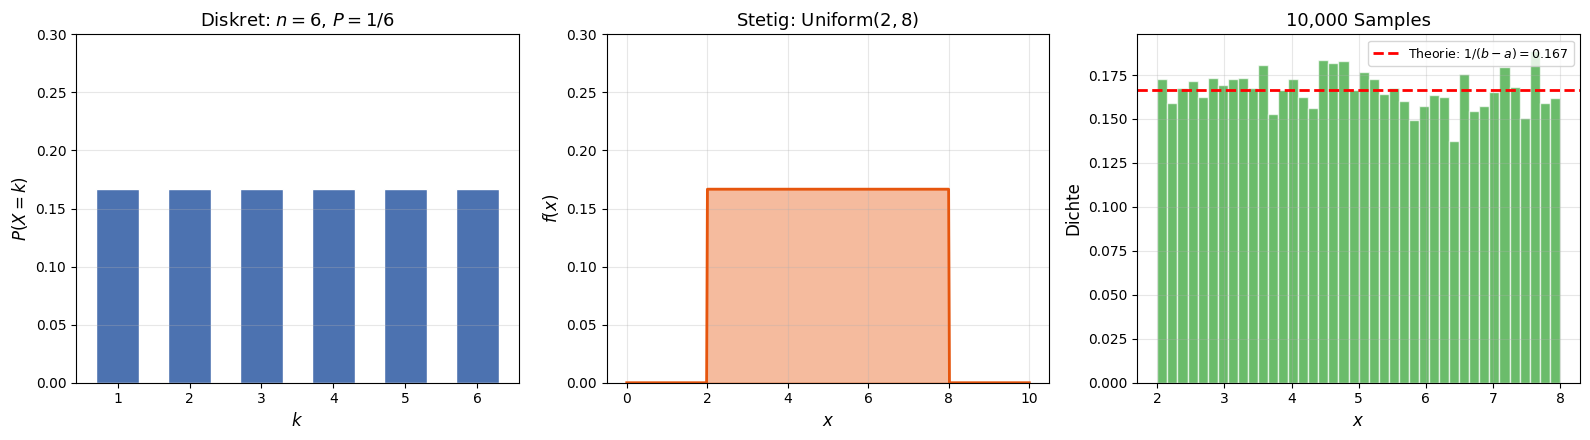

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# ============================================================
# KONFIGURATION - Gleichverteilung: diskret vs. stetig
# ============================================================

Uniform_Config = {
    "diskret_n": 6,
    "stetig_a": 2,
    "stetig_b": 8,
    "n_samples": 10_000,
}

# ============================================================
# VISUALISIERUNG - Diskret vs. stetig + Sampling-Histogramm
# ============================================================

def visualisiere_uniform(config):
    """Zeigt diskrete und stetige Gleichverteilung mit Sampling."""
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

    # --- Links: Diskrete Gleichverteilung ---
    ax = axes[0]
    n = config["diskret_n"]
    k = np.arange(1, n + 1)
    p = np.ones(n) / n
    ax.bar(k, p, color="#4C72B0", edgecolor="white", width=0.6)
    ax.set_xlabel("$k$", fontsize=12)
    ax.set_ylabel("$P(X = k)$", fontsize=12)
    ax.set_title(f"Diskret: $n = {n}$, $P = 1/{n}$", fontsize=13)
    ax.set_xticks(k)
    ax.set_ylim(0, 0.3)
    ax.grid(True, alpha=0.3, axis="y")

    # --- Mitte: Stetige Gleichverteilung (PDF) ---
    ax = axes[1]
    a, b = config["stetig_a"], config["stetig_b"]
    x = np.linspace(a - 2, b + 2, 500)
    pdf = np.where((x >= a) & (x <= b), 1 / (b - a), 0)
    ax.fill_between(x, pdf, alpha=0.4, color="#E6550D")
    ax.plot(x, pdf, color="#E6550D", linewidth=2)
    ax.set_xlabel("$x$", fontsize=12)
    ax.set_ylabel("$f(x)$", fontsize=12)
    ax.set_title(f"Stetig: Uniform$({a}, {b})$", fontsize=13)
    ax.set_ylim(0, 0.3)
    ax.grid(True, alpha=0.3)

    # --- Rechts: Sampling → Histogramm ---
    ax = axes[2]
    samples = np.random.uniform(a, b, config["n_samples"])
    ax.hist(samples, bins=40, density=True, color="#2CA02C", edgecolor="white", alpha=0.7)
    ax.axhline(1 / (b - a), color="red", linestyle="--", linewidth=2,
               label=f"Theorie: $1/(b-a) = {1/(b-a):.3f}$")
    ax.set_xlabel("$x$", fontsize=12)
    ax.set_ylabel("Dichte", fontsize=12)
    ax.set_title(f"{config['n_samples']:,} Samples", fontsize=13)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

visualisiere_uniform(Uniform_Config)

### 2. Exponentialverteilung

Stellen wir uns ein konkretes Szenario vor: Ein Server stürzt im Schnitt einmal pro Woche ab - völlig zufällig, ohne Vorwarnung. Die **Exponentialverteilung** modelliert genau solche **Wartezeiten** zwischen zufälligen Ereignissen. Sie ist das stetige Gegenstück zur geometrischen Verteilung.

#### Dichtefunktion

$$f(x) = \lambda \, e^{-\lambda x} \qquad \text{für } x \geq 0$$

$$E(X) = \frac{1}{\lambda} \qquad \text{Var}(X) = \frac{1}{\lambda^2}$$

Der Parameter $\lambda$ ist die **Rate** (Ereignisse pro Zeiteinheit). Je größer $\lambda$, desto kürzer die erwartete Wartezeit.

#### Gedächtnislosigkeit

Die zentrale (und zunächst kontraintuitive) Eigenschaft: Die verbleibende Wartezeit hängt *nicht* davon ab, wie lange man bereits gewartet hat:

$$P(X > s + t \mid X > s) = P(X > t)$$

Bei unserem Server: Ob er seit 3 Tagen oder seit 3 Wochen läuft - die Wahrscheinlichkeit eines Absturzes in der nächsten Stunde bleibt gleich. Das passt zu Prozessen ohne „Verschleiß" (radioaktiver Zerfall, spontane Ausfälle), aber natürlich nicht zu allem (Autoteile verschleißen sehr wohl).

#### Zusammenhang mit Poisson

Wenn Ereignisse poissonverteilt mit Rate $\lambda$ auftreten, dann ist die **Wartezeit** zwischen zwei aufeinanderfolgenden Ereignissen exponentialverteilt mit demselben $\lambda$. Die beiden Verteilungen sind zwei Seiten derselben Medaille: Poisson zählt *wie viele* Ereignisse, Exponential misst *wie lange* dazwischen.

In der Praxis taucht die Exponentialverteilung bei **Survival Analysis** (Überlebenszeiten), in **Queueing Theory** (Ankunftszeiten), und als Baustein der Gamma-Verteilung auf, die wir gleich kennenlernen.

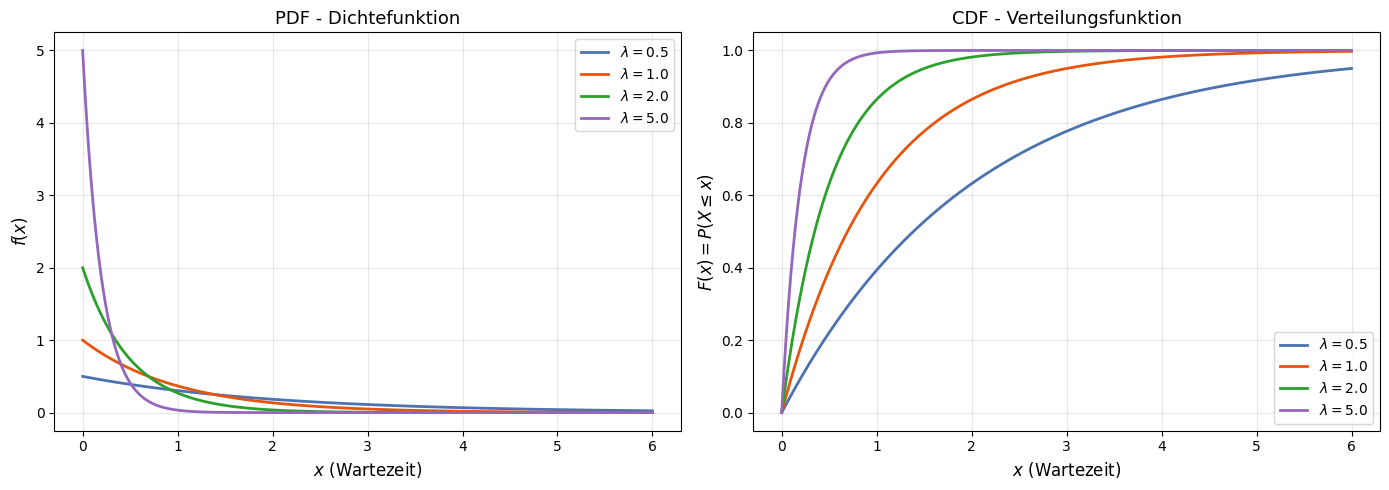

In [10]:
# ============================================================
# KONFIGURATION - Exponentialverteilung
# ============================================================

Exponential_Config = {
    "lambdas": [0.5, 1.0, 2.0, 5.0],
    "farben": ["#4C72B0", "#E6550D", "#2CA02C", "#9467BD"],
}

# ============================================================
# VISUALISIERUNG - PDF und CDF für verschiedene λ
# ============================================================

def visualisiere_exponential(config):
    """Zeigt PDF und CDF der Exponentialverteilung für verschiedene Raten."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    x = np.linspace(0, 6, 500)

    for lam, farbe in zip(config["lambdas"], config["farben"]):
        pdf = lam * np.exp(-lam * x)
        cdf = 1 - np.exp(-lam * x)

        axes[0].plot(x, pdf, color=farbe, linewidth=2, label=rf"$\lambda = {lam}$")
        axes[1].plot(x, cdf, color=farbe, linewidth=2, label=rf"$\lambda = {lam}$")

    axes[0].set_xlabel("$x$ (Wartezeit)", fontsize=12)
    axes[0].set_ylabel("$f(x)$", fontsize=12)
    axes[0].set_title("PDF - Dichtefunktion", fontsize=13)
    axes[0].legend(fontsize=10)
    axes[0].grid(True, alpha=0.3)

    axes[1].set_xlabel("$x$ (Wartezeit)", fontsize=12)
    axes[1].set_ylabel("$F(x) = P(X \\leq x)$", fontsize=12)
    axes[1].set_title("CDF - Verteilungsfunktion", fontsize=13)
    axes[1].legend(fontsize=10)
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

visualisiere_exponential(Exponential_Config)

### 3. Beta-Verteilung

Bisher haben unsere Verteilungen Daten modelliert: Würfelergebnisse, Wartezeiten, Häufigkeiten. Aber was, wenn man den **Parameter selbst** nicht kennt? Beispiel: Eine Website hat eine Conversion-Rate $p$ - aber wie groß $p$ genau ist, wissen wir noch nicht. Wir brauchen eine *Verteilung über Wahrscheinlichkeiten*.

Genau das leistet die **Beta-Verteilung**: Sie lebt auf dem Intervall $[0, 1]$ und kann mit nur zwei Parametern $\alpha > 0$ und $\beta > 0$ eine erstaunliche Formenvielfalt annehmen.

#### Dichtefunktion

$$f(x; \alpha, \beta) = \frac{x^{\alpha-1}(1-x)^{\beta-1}}{B(\alpha, \beta)} \qquad \text{für } 0 \leq x \leq 1$$

Der Nenner $B(\alpha, \beta)$ ist die **Beta-Funktion** - ein reiner Normierungsfaktor, der sicherstellt, dass die Dichte auf 1 integriert. Sie hängt mit der Gamma-Funktion zusammen: $B(\alpha, \beta) = \frac{\Gamma(\alpha)\,\Gamma(\beta)}{\Gamma(\alpha+\beta)}$. Die Parameter $\alpha$ und $\beta$ müssen lediglich positiv reell sein (keine komplexen Zahlen nötig - das wäre reine Funktionentheorie).

$$E(X) = \frac{\alpha}{\alpha + \beta} \qquad \text{Var}(X) = \frac{\alpha\beta}{(\alpha+\beta)^2(\alpha+\beta+1)}$$

#### Spezialfälle

| $\alpha$ | $\beta$ | Form | Entspricht |
|----------|---------|------|------------|
| $1$ | $1$ | Uniform | $\text{Uniform}(0,1)$ |
| $< 1$ | $< 1$ | U-Form | Extrem an den Rändern |
| $> 1$ | $> 1$ | Glocke | Konzentriert in der Mitte |
| $\alpha > \beta$ | | Rechtslastig | Hohe Werte wahrscheinlicher |
| $\alpha < \beta$ | | Linkslastig | Niedrige Werte wahrscheinlicher |

#### Konjugierter Prior: Was das heißt und warum es so elegant ist

Die Beta-Verteilung ist der **konjugierte Prior** der Binomialverteilung. Das bedeutet: Startet man mit einem Beta-Prior und beobachtet binomiale Daten, ist der Posterior *wieder* eine Beta-Verteilung:

$$\text{Prior: } \text{Beta}(\alpha, \beta) \;\;+\;\; k \text{ Treffer in } n \text{ Versuchen} \;\;\Rightarrow\;\; \text{Posterior: } \text{Beta}(\alpha + k,\; \beta + n - k)$$

Man addiert einfach Treffer und Nieten auf die bestehenden Parameter - kein Integral lösen, kein Rechner nötig. In der Praxis bedeutet das: Beim **A/B-Testing** startet man mit einem vagen Prior (z.B. $\text{Beta}(1,1)$ = „ich weiss nichts"), und nach jeder Beobachtung wird die Schätzung automatisch schärfer. Die rechte Grafik unten zeigt genau diesen Prozess.

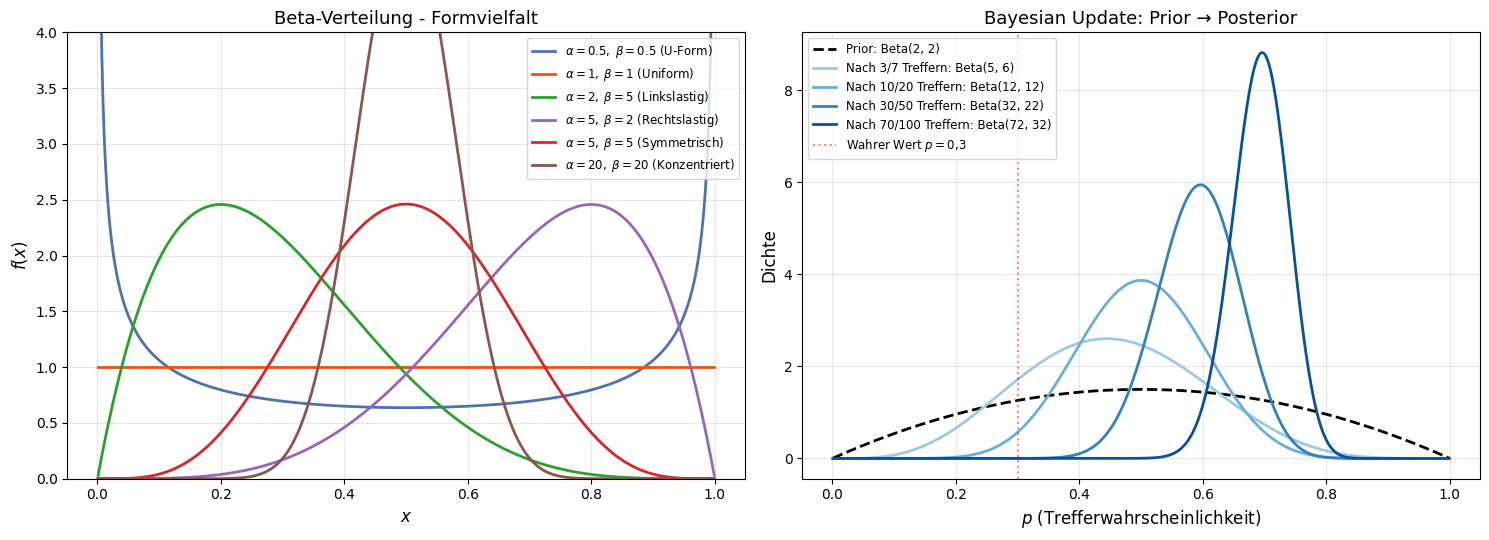

In [11]:
# ============================================================
# KONFIGURATION - Beta-Verteilung
# ============================================================

Beta_Config = {
    "formen": [
        (0.5, 0.5, "U-Form"),
        (1, 1, "Uniform"),
        (2, 5, "Linkslastig"),
        (5, 2, "Rechtslastig"),
        (5, 5, "Symmetrisch"),
        (20, 20, "Konzentriert"),
    ],
    "farben": ["#4C72B0", "#E6550D", "#2CA02C", "#9467BD", "#D62728", "#8C564B"],
    "bayesian_update": {
        "prior_alpha": 2,
        "prior_beta": 2,
        "beobachtungen": [(3, 7), (10, 20), (30, 50), (70, 100)],
    },
}

# ============================================================
# VISUALISIERUNG - Formvielfalt + Bayesian Update
# ============================================================

def visualisiere_beta(config):
    """Zeigt die Formenvielfalt der Beta-Verteilung und ein Bayesian Update."""
    x = np.linspace(0.001, 0.999, 500)
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

    # --- Links: Verschiedene (α, β)-Kombinationen ---
    ax = axes[0]
    for (a, b, name), farbe in zip(config["formen"], config["farben"]):
        pdf = stats.beta.pdf(x, a, b)
        ax.plot(x, pdf, linewidth=2, color=farbe,
                label=rf"$\alpha={a},\;\beta={b}$ ({name})")

    ax.set_xlabel("$x$", fontsize=12)
    ax.set_ylabel("$f(x)$", fontsize=12)
    ax.set_title("Beta-Verteilung - Formvielfalt", fontsize=13)
    ax.legend(fontsize=8.5, loc="upper right")
    ax.set_ylim(0, 4)
    ax.grid(True, alpha=0.3)

    # --- Rechts: Bayesian Update (Prior → Posterior) ---
    ax = axes[1]
    bu = config["bayesian_update"]
    a0, b0 = bu["prior_alpha"], bu["prior_beta"]

    ax.plot(x, stats.beta.pdf(x, a0, b0), "k--", linewidth=2,
            label=f"Prior: Beta({a0}, {b0})")

    update_farben = ["#9ECAE1", "#6BAED6", "#3182BD", "#08519C"]
    for (k, n), farbe in zip(bu["beobachtungen"], update_farben):
        a_post = a0 + k
        b_post = b0 + (n - k)
        ax.plot(x, stats.beta.pdf(x, a_post, b_post), linewidth=2, color=farbe,
                label=f"Nach {k}/{n} Treffern: Beta({a_post}, {b_post})")

    ax.axvline(0.3, color="red", linestyle=":", alpha=0.5, label="Wahrer Wert $p = 0{,}3$")
    ax.set_xlabel("$p$ (Trefferwahrscheinlichkeit)", fontsize=12)
    ax.set_ylabel("Dichte", fontsize=12)
    ax.set_title("Bayesian Update: Prior → Posterior", fontsize=13)
    ax.legend(fontsize=8.5)
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

visualisiere_beta(Beta_Config)

### 4. Gamma-Verteilung

Die Exponentialverteilung modelliert die Wartezeit auf *ein* Ereignis. Was, wenn man auf das **$k$-te** warten muss - z.B. den dritten Serverausfall, oder den fünften Kundenanruf? Dann summiert man $k$ exponentialverteilte Wartezeiten, und heraus kommt die **Gamma-Verteilung**.

#### Dichtefunktion

$$f(x; k, \theta) = \frac{x^{k-1} \, e^{-x/\theta}}{\theta^k \, \Gamma(k)} \qquad \text{für } x > 0$$

Die **Gamma-Funktion** $\Gamma(k)$ im Nenner ist - wie bei der Beta-Verteilung - ein Normierungsfaktor. Für natürliche Zahlen gilt einfach $\Gamma(k) = (k-1)!$, aber $\Gamma$ verallgemeinert die Fakultät auf alle positiven reellen Zahlen.

$$E(X) = k\theta \qquad \text{Var}(X) = k\theta^2$$

Es gibt zwei gängige Parametrisierungen:
- **Shape-Scale**: $(k, \theta)$ - wie oben
- **Shape-Rate**: $(k, \beta)$ mit $\beta = 1/\theta$ - häufig in Bayesian-Literatur

#### Spezialfälle

Die Gamma-Verteilung ist eine regelrechte „Dachverteilung", unter der einiges versammelt ist:

| Parameter | Verteilung | Beschreibung |
|-----------|-----------|--------------|
| $k = 1$ | Exponential$(\lambda = 1/\theta)$ | Wartezeit auf *ein* Ereignis |
| $k = n/2,\; \theta = 2$ | $\chi^2(n)$ | Chi-Quadrat mit $n$ Freiheitsgraden |
| $k \in \mathbb{N}$ | Erlang$(k, \lambda)$ | Wartezeit auf $k$ Ereignisse |

Das rechte Diagramm unten demonstriert den Zusammenhang empirisch: Man sieht, wie die Summe von immer mehr Exponential-Wartezeiten exakt der theoretischen Gamma-Kurve entspricht.

Analog zur Beta-Verteilung ist die Gamma-Verteilung ebenfalls ein konjugierter Prior - diesmal für die **Poisson-Rate** $\lambda$ und die **Präzision** $\tau = 1/\sigma^2$ der Normalverteilung. In der Bayesian-Modellierung taucht sie deshalb überall dort auf, wo man Unsicherheit über Raten oder Varianzen ausdrücken will.

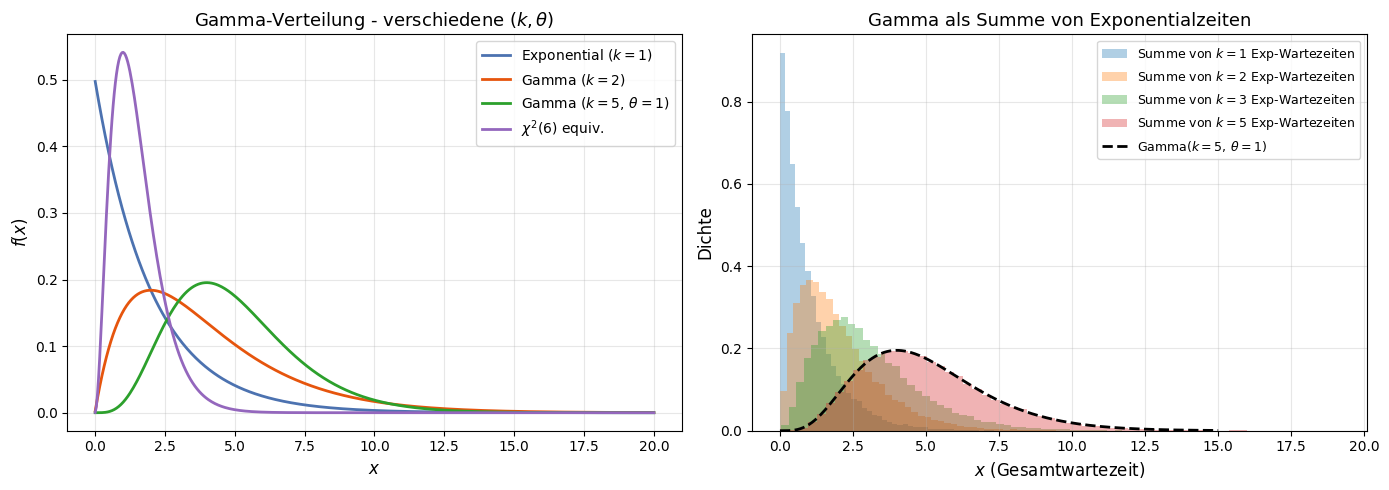

In [12]:
# ============================================================
# KONFIGURATION - Gamma-Verteilung und Spezialfälle
# ============================================================

Gamma_Config = {
    "varianten": [
        (1, 2, "Exponential ($k=1$)"),
        (2, 2, "Gamma ($k=2$)"),
        (5, 1, "Gamma ($k=5,\\, \\theta=1$)"),
        (3, 0.5, r"$\chi^2(6)$ equiv."),
    ],
    "farben": ["#4C72B0", "#E6550D", "#2CA02C", "#9467BD"],
}

# ============================================================
# VISUALISIERUNG - Gamma-Familie mit Spezialfällen
# ============================================================

def visualisiere_gamma(config):
    """Zeigt die Gamma-Verteilung als Familie mit Exponential und Chi² als Spezialfälle."""
    x = np.linspace(0.01, 20, 500)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # --- Links: Verschiedene (k, θ) ---
    ax = axes[0]
    for (k, theta, name), farbe in zip(config["varianten"], config["farben"]):
        pdf = stats.gamma.pdf(x, a=k, scale=theta)
        ax.plot(x, pdf, linewidth=2, color=farbe, label=name)

    ax.set_xlabel("$x$", fontsize=12)
    ax.set_ylabel("$f(x)$", fontsize=12)
    ax.set_title("Gamma-Verteilung - verschiedene $(k, \\theta)$", fontsize=13)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)

    # --- Rechts: Exponential → Gamma (Summe von Wartezeiten) ---
    ax = axes[1]
    np.random.seed(42)
    n_sim = 50_000
    lam = 1.0
    for k in [1, 2, 3, 5]:
        # Summe von k exponentialverteilten Wartezeiten
        wartezeiten = np.sum(np.random.exponential(1 / lam, size=(n_sim, k)), axis=1)
        ax.hist(wartezeiten, bins=60, density=True, alpha=0.35,
                label=f"Summe von $k={k}$ Exp-Wartezeiten")

    # Theoretische Gamma-Kurve für k=5
    x_th = np.linspace(0, 15, 300)
    ax.plot(x_th, stats.gamma.pdf(x_th, a=5, scale=1/lam), "k--", linewidth=2,
            label=r"Gamma$(k=5,\, \theta=1)$")

    ax.set_xlabel("$x$ (Gesamtwartezeit)", fontsize=12)
    ax.set_ylabel("Dichte", fontsize=12)
    ax.set_title("Gamma als Summe von Exponentialzeiten", fontsize=13)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

visualisiere_gamma(Gamma_Config)

### 5. Multinomialverteilung

Die Binomialverteilung hat zwei Ausgänge: Treffer oder Niete. Aber was, wenn ein Würfel 6 Seiten hat? Oder ein Klassifikator 10 Klassen unterscheidet? Die **Multinomialverteilung** verallgemeinert die Binomialverteilung auf **$K$ Kategorien** mit Wahrscheinlichkeiten $p_1, \ldots, p_K$ (wobei $\sum p_i = 1$).

#### Formel

Bei $n$ unabhängigen Versuchen:

$$P(X_1 = x_1, \ldots, X_K = x_K) = \frac{n!}{x_1! \cdot x_2! \cdots x_K!} \cdot p_1^{x_1} \cdot p_2^{x_2} \cdots p_K^{x_K}$$

$$E(X_i) = n \cdot p_i \qquad \text{Var}(X_i) = n \cdot p_i \cdot (1 - p_i)$$

Schaut man sich nur *eine* der $K$ Komponenten an, ist $X_i \sim \text{Bin}(n, p_i)$ - die Marginalen sind binomialverteilt.

#### Warum das im ML zentral ist

Wenn ein Klassifikator über seine Softmax-Schicht die Wahrscheinlichkeiten $(p_1, \ldots, p_K)$ für $K$ Klassen ausgibt, ist ein einzelner Datenpunkt eine Multinomialverteilung mit $n = 1$ (auch **kategorische Verteilung** genannt). Der **Cross-Entropy Loss** $-\sum_i y_i \log(p_i)$, den man in fast jedem Klassifikationsproblem minimiert, ist nichts anderes als die negative Log-Likelihood der Multinomialverteilung.

Auch in der Textverarbeitung (NLP) begegnet man ihr: Bag-of-Words-Modelle behandeln Wortvorkommen als multinomialverteilt. Und der konjugierte Prior? Die **Dirichlet-Verteilung** - eine Verallgemeinerung der Beta-Verteilung auf den $K$-dimensionalen Simplex.

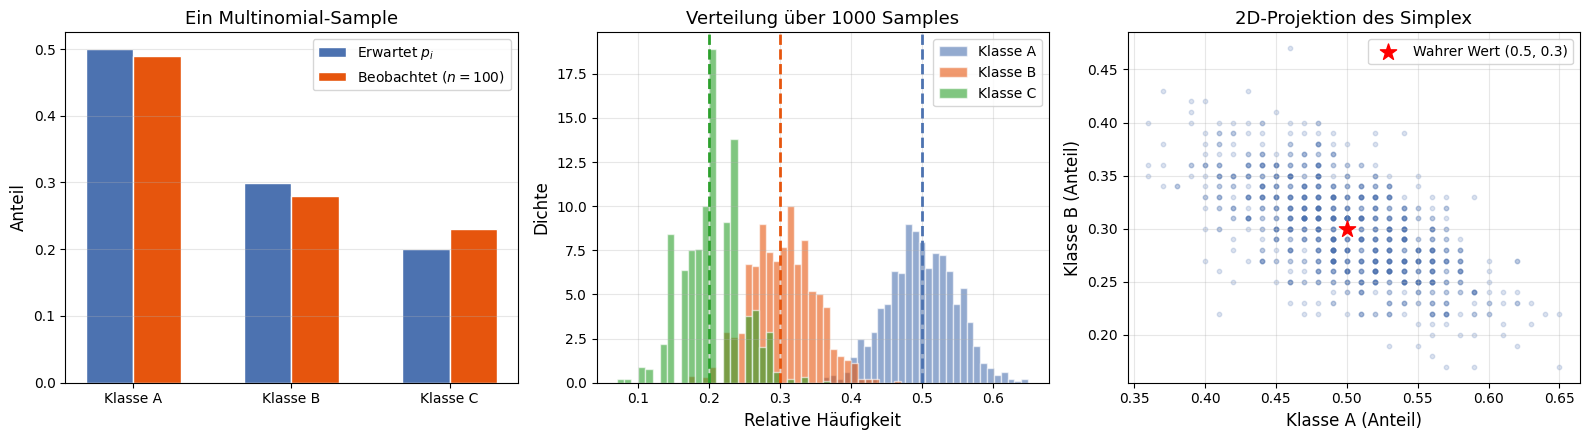

In [13]:
# ============================================================
# KONFIGURATION - Multinomial: Simplex und Sampling
# ============================================================

Multinomial_Config = {
    "kategorien": ["Klasse A", "Klasse B", "Klasse C"],
    "wahre_p": [0.5, 0.3, 0.2],
    "n_versuche": 100,
    "n_samples": 1000,
}

# ============================================================
# VISUALISIERUNG - Simplex-Darstellung (3 Kategorien)
# ============================================================

def visualisiere_multinomial(config):
    """Zeigt Multinomial-Sampling auf dem 2-Simplex."""
    p = np.array(config["wahre_p"])
    n = config["n_versuche"]
    labels = config["kategorien"]

    np.random.seed(42)
    samples = np.random.multinomial(n, p, size=config["n_samples"])
    freq = samples / n  # Relative Häufigkeiten

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

    # --- Links: Erwartete vs. beobachtete Häufigkeiten (ein Sample) ---
    ax = axes[0]
    x_pos = np.arange(len(labels))
    breite = 0.3
    ax.bar(x_pos - breite/2, p, width=breite, color="#4C72B0", edgecolor="white",
           label="Erwartet $p_i$")
    ax.bar(x_pos + breite/2, freq[0], width=breite, color="#E6550D", edgecolor="white",
           label=f"Beobachtet ($n={n}$)")
    ax.set_xticks(x_pos)
    ax.set_xticklabels(labels)
    ax.set_ylabel("Anteil", fontsize=12)
    ax.set_title("Ein Multinomial-Sample", fontsize=13)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3, axis="y")

    # --- Mitte: Streuung über viele Samples ---
    ax = axes[1]
    for i, (label, farbe) in enumerate(zip(labels, ["#4C72B0", "#E6550D", "#2CA02C"])):
        ax.hist(freq[:, i], bins=30, density=True, alpha=0.6, color=farbe,
                edgecolor="white", label=label)
        ax.axvline(p[i], color=farbe, linestyle="--", linewidth=2)

    ax.set_xlabel("Relative Häufigkeit", fontsize=12)
    ax.set_ylabel("Dichte", fontsize=12)
    ax.set_title(f"Verteilung über {config['n_samples']} Samples", fontsize=13)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)

    # --- Rechts: 2D-Simplex (Klasse A vs. Klasse B) ---
    ax = axes[2]
    ax.scatter(freq[:, 0], freq[:, 1], alpha=0.2, s=10, color="#4C72B0")
    ax.scatter(p[0], p[1], color="red", s=150, zorder=5, marker="*",
               label=f"Wahrer Wert ({p[0]}, {p[1]})")
    ax.set_xlabel(f"{labels[0]} (Anteil)", fontsize=12)
    ax.set_ylabel(f"{labels[1]} (Anteil)", fontsize=12)
    ax.set_title("2D-Projektion des Simplex", fontsize=13)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

visualisiere_multinomial(Multinomial_Config)

### 6. Multivariate Normalverteilung

Bisher waren alle Verteilungen eindimensional (oder diskret mehrdimensional wie die Multinomiale). Aber reale Datensätze haben fast immer **mehrere Features** - und die können korreliert sein. Die **multivariate Normalverteilung** verallgemeinert die Gauß-Glocke auf $d$ Dimensionen.

Statt $\mu$ und $\sigma^2$ hat man jetzt einen **Mittelwertvektor** $\boldsymbol{\mu} \in \mathbb{R}^d$ und eine **Kovarianzmatrix** $\boldsymbol{\Sigma} \in \mathbb{R}^{d \times d}$.

#### Dichtefunktion

$$f(\mathbf{x}) = \frac{1}{\sqrt{(2\pi)^d \det(\boldsymbol{\Sigma})}} \exp\!\left(-\frac{1}{2}(\mathbf{x} - \boldsymbol{\mu})^\top \boldsymbol{\Sigma}^{-1} (\mathbf{x} - \boldsymbol{\mu})\right)$$

Zwei Dinge fallen auf:

1. **$\det(\boldsymbol{\Sigma})$** - die **Determinante** der Kovarianzmatrix. Sie misst, wie viel „Volumen" die Verteilung einnimmt. Große Determinante → weit gestreut, niedriger Peak. Kleine Determinante → eng konzentriert, hoher Peak. Für eine $2 \times 2$-Matrix: $\det\begin{pmatrix} a & b \\ c & d \end{pmatrix} = ad - bc$.

2. **$(\mathbf{x} - \boldsymbol{\mu})^\top \boldsymbol{\Sigma}^{-1} (\mathbf{x} - \boldsymbol{\mu})$** - die **Mahalanobis-Distanz**. Sie misst den Abstand eines Punktes zum Mittelwert, aber *gewichtet nach der Kovarianzstruktur*. In Richtungen mit hoher Varianz „zählt" dieselbe Strecke weniger als in Richtungen mit niedriger Varianz.

#### Die Kovarianzmatrix $\Sigma$

Die Kovarianzmatrix codiert, wie die Dimensionen zusammenhängen:
- **Diagonale** $\Sigma_{ii} = \sigma_i^2$: Varianz der $i$-ten Dimension
- **Nebendiagonale** $\Sigma_{ij}$: Kovarianz zwischen Dimension $i$ und $j$
  - $> 0$: positiv korreliert (steigen gemeinsam)
  - $= 0$: unkorreliert (achsenparallele Ellipse)
  - $< 0$: negativ korreliert (gegenläufig)

Geometrisch formen die Konturlinien gleicher Dichte **Ellipsen**, deren Achsen und Orientierung durch die Eigenwerte und Eigenvektoren von $\Sigma$ bestimmt werden. Das sieht man gut in den vier Beispielen unten.

Die multivariate Normalverteilung steckt in vielen Algorithmen: **Gaussian Mixture Models** (jeder Cluster eine Gauß-Ellipse), **PCA** (Eigenvektoren der Kovarianzmatrix), **Variational Autoencoders** (Latent-Space als multivariate Normalverteilung) und **Gaussian Processes** (Verteilungen über ganze Funktionen).

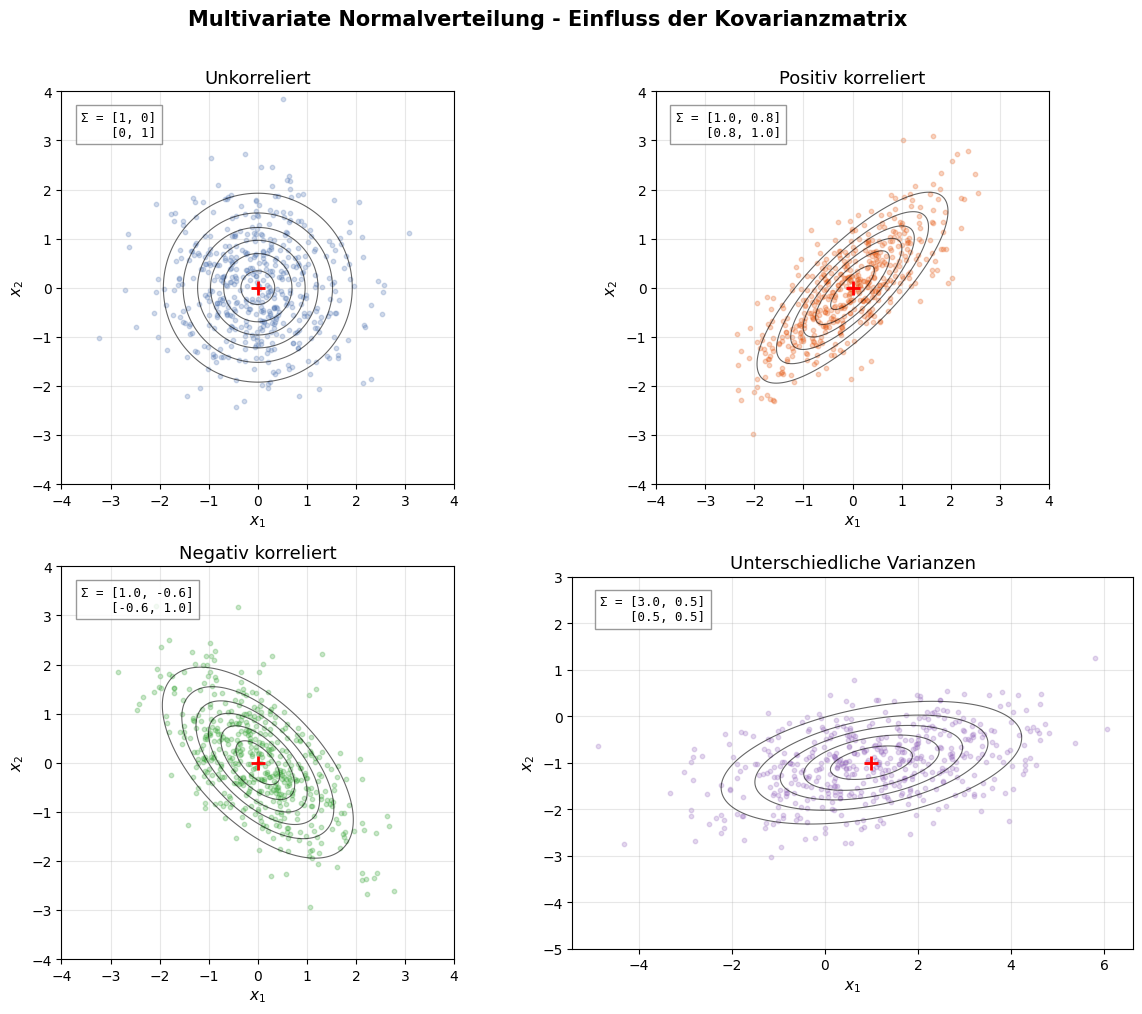

In [15]:
# ============================================================
# KONFIGURATION - Multivariate Normalverteilung
# ============================================================

MVN_Config = {
    "beispiele": [
        {
            "name": "Unkorreliert",
            "mu": [0, 0],
            "sigma": [[1, 0], [0, 1]],
            "farbe": "#4C72B0",
        },
        {
            "name": "Positiv korreliert",
            "mu": [0, 0],
            "sigma": [[1, 0.8], [0.8, 1]],
            "farbe": "#E6550D",
        },
        {
            "name": "Negativ korreliert",
            "mu": [0, 0],
            "sigma": [[1, -0.6], [-0.6, 1]],
            "farbe": "#2CA02C",
        },
        {
            "name": "Unterschiedliche Varianzen",
            "mu": [1, -1],
            "sigma": [[3, 0.5], [0.5, 0.5]],
            "farbe": "#9467BD",
        },
    ],
    "n_samples": 500,
}

# ============================================================
# VISUALISIERUNG - 2D-Konturen und Einfluss der Kovarianz
# ============================================================

def visualisiere_mvn(config):
    """Zeigt vier verschiedene 2D-Normalverteilungen als Kontur + Scatter."""
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    axes = axes.flatten()

    np.random.seed(42)

    for ax, bsp in zip(axes, config["beispiele"]):
        mu = np.array(bsp["mu"])
        sigma = np.array(bsp["sigma"])

        # Samples zeichnen
        samples = np.random.multivariate_normal(mu, sigma, config["n_samples"])
        ax.scatter(samples[:, 0], samples[:, 1], alpha=0.25, s=10, color=bsp["farbe"])

        # Konturlinien
        x_range = np.linspace(mu[0] - 4, mu[0] + 4, 200)
        y_range = np.linspace(mu[1] - 4, mu[1] + 4, 200)
        X, Y = np.meshgrid(x_range, y_range)
        pos = np.dstack((X, Y))
        rv = stats.multivariate_normal(mu, sigma)
        Z = rv.pdf(pos)

        ax.contour(X, Y, Z, levels=6, colors="k", linewidths=0.8, alpha=0.6)

        # Mittelwert markieren
        ax.scatter(*mu, color="red", s=100, marker="+", linewidths=2, zorder=5)

        # Kovarianzmatrix als Text
        cov_text = (f"\u03a3 = [{sigma[0][0]}, {sigma[0][1]}]\n"
                    f"    [{sigma[1][0]}, {sigma[1][1]}]")
        ax.text(0.05, 0.95, cov_text, transform=ax.transAxes, fontsize=9,
                verticalalignment="top", family="monospace",
                bbox=dict(facecolor="white", alpha=0.8, edgecolor="gray"))

        ax.set_title(bsp["name"], fontsize=13)
        ax.set_xlabel("$x_1$", fontsize=11)
        ax.set_ylabel("$x_2$", fontsize=11)
        ax.set_aspect("equal")
        ax.grid(True, alpha=0.3)

    fig.suptitle("Multivariate Normalverteilung - Einfluss der Kovarianzmatrix",
                 fontsize=15, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()

visualisiere_mvn(MVN_Config)

### 7. Verteilungs-Landkarte

Alle Verteilungen aus diesem und dem vorigen Notebook bilden ein zusammenhängendes Netzwerk. Das Diagramm unten zeigt die drei Arten von Beziehungen:

#### Durchgezogene Linien - Spezialfälle
Verteilung A *ist* Verteilung B mit eingeschränkten Parametern. Man muss nicht jede neu lernen - versteht man die allgemeinere, hat man den Spezialfall gratis:

| Von → Zu | Was passiert |
|----------|-------------|
| Bernoulli → Binomial | Ein Bernoulli-Versuch ist Binomial mit $n=1$. Summiert man $n$ davon, entsteht Binomial. |
| Exponential → Gamma | Exponential ist Gamma mit $k=1$. Wartezeit auf ein vs. auf $k$ Ereignisse. |
| Gamma → Chi² | $\chi^2(n) = \text{Gamma}(n/2,\, 2)$ - taucht in Hypothesentests auf. |
| Beta $(1,1)$ → Uniform | Beta mit beiden Parametern auf 1 wird flach - „ich weiss nichts". |
| Normal → Multiv. Normal | Die 1D-Normalverteilung ist der Spezialfall $d=1$. |
| Binomial → Multinomial | Binomial hat 2 Ausgänge, Multinomial hat $K$. Bei $K=2$ sind sie identisch. |

#### Gestrichelte Linien - Grenzwerte
Verteilung A *nähert sich* Verteilung B unter bestimmten Bedingungen:

| Von → Zu | Bedingung |
|----------|-----------|
| Binomial → Poisson | $n \to \infty$, $p \to 0$, aber $np = \lambda$ konstant. Deshalb modelliert Poisson *seltene* Ereignisse. |
| Binomial → Normal | $n$ groß - der **Zentrale Grenzwertsatz** in Aktion. |

#### Gepunktete Linien - Konjugierte Priors
Verteilung A ist der „natürliche" Bayesian-Prior für Verteilung B. Der Posterior bleibt in derselben Familie:

| Prior → Likelihood | Bedeutung |
|-------------------|-----------|
| Beta → Binomial | Unsicherheit über $p$ modellieren. Nach Beobachtungen: Beta-Posterior mit schärferen Parametern. |
| Gamma → Poisson | Unsicherheit über die Rate $\lambda$. Gleiches Prinzip, gleiche Eleganz. |

#### Diskret vs. Stetig

| Diskrete Verteilungen | Stetige Verteilungen |
|----------------------|---------------------|
| Bernoulli, Binomial | Normal, Multivariate Normal |
| Poisson | Exponential, Gamma |
| Multinomial | Uniform, Beta |

---

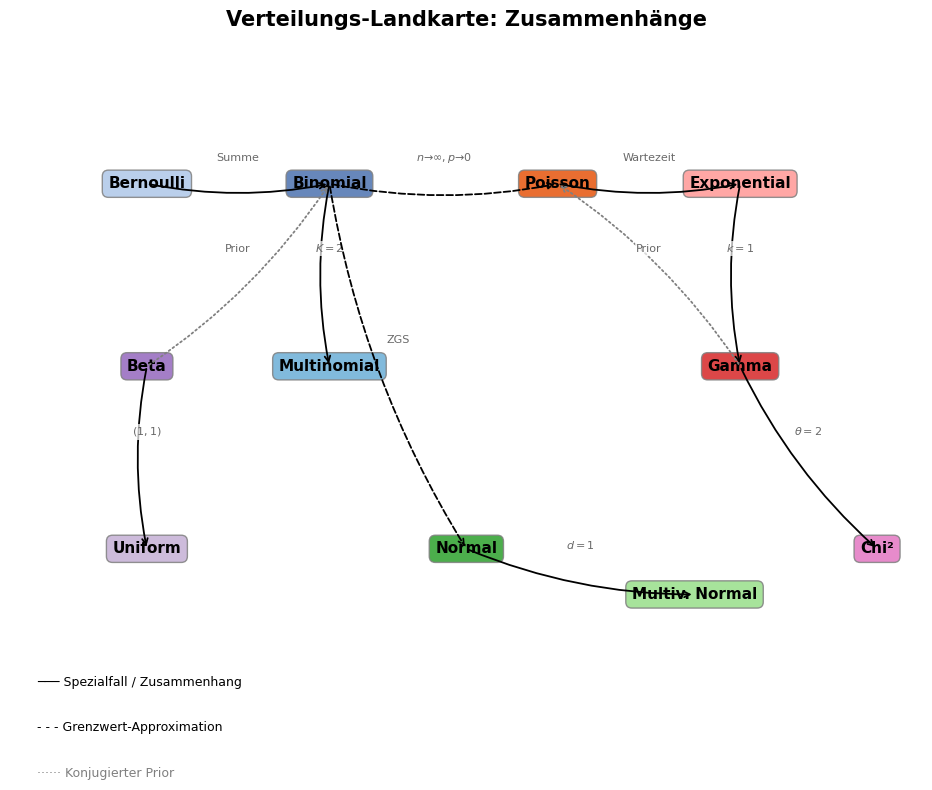

In [16]:
# ============================================================
# VISUALISIERUNG - Verteilungs-Beziehungsdiagramm
# ============================================================

def visualisiere_landkarte():
    """Zeichnet ein Beziehungsdiagramm aller Verteilungen."""
    fig, ax = plt.subplots(figsize=(14, 8))
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 8)
    ax.set_aspect("equal")
    ax.axis("off")

    # --- Knoten: Position, Name, Farbe ---
    knoten = {
        "Bernoulli":    (1.5, 6.5, "#AEC7E8"),
        "Binomial":     (3.5, 6.5, "#4C72B0"),
        "Multinomial":  (3.5, 4.5, "#6BAED6"),
        "Poisson":      (6.0, 6.5, "#E6550D"),
        "Exponential":  (8.0, 6.5, "#FF9896"),
        "Gamma":        (8.0, 4.5, "#D62728"),
        "Normal":       (5.0, 2.5, "#2CA02C"),
        "Multiv. Normal": (7.5, 2.0, "#98DF8A"),
        "Beta":         (1.5, 4.5, "#9467BD"),
        "Uniform":      (1.5, 2.5, "#C5B0D5"),
        "Chi²":         (9.5, 2.5, "#E377C2"),
    }

    for name, (x, y, farbe) in knoten.items():
        box = dict(boxstyle="round,pad=0.4", facecolor=farbe, edgecolor="gray", alpha=0.85)
        ax.text(x, y, name, fontsize=11, fontweight="bold", ha="center", va="center", bbox=box)

    # --- Kanten: (von, zu, label, stil) ---
    kanten = [
        ("Bernoulli", "Binomial", "Summe", "-"),
        ("Binomial", "Multinomial", "$K=2$", "-"),
        ("Binomial", "Poisson", "$n→∞, p→0$", "--"),
        ("Binomial", "Normal", "ZGS", "--"),
        ("Poisson", "Exponential", "Wartezeit", "-"),
        ("Exponential", "Gamma", "$k=1$", "-"),
        ("Gamma", "Chi²", "$θ=2$", "-"),
        ("Normal", "Multiv. Normal", "$d=1$", "-"),
        ("Beta", "Uniform", "$(1,1)$", "-"),
        ("Beta", "Binomial", "Prior", ":"),
        ("Gamma", "Poisson", "Prior", ":"),
    ]

    for von, zu, label, stil in kanten:
        x1, y1, _ = knoten[von]
        x2, y2, _ = knoten[zu]
        ls = {"--": "dashed", "-": "solid", ":": "dotted"}[stil]

        ax.annotate(
            "", xy=(x2, y2), xytext=(x1, y1),
            arrowprops=dict(arrowstyle="->", lw=1.3, linestyle=ls,
                            color="gray" if stil == ":" else "black",
                            connectionstyle="arc3,rad=0.1"),
        )
        # Label am Mittelpunkt
        mx, my = (x1 + x2) / 2, (y1 + y2) / 2
        ax.text(mx, my + 0.25, label, fontsize=8, ha="center", color="dimgray",
                bbox=dict(facecolor="white", alpha=0.7, edgecolor="none", pad=1))

    # Legende
    ax.text(0.3, 1.0, "─── Spezialfall / Zusammenhang", fontsize=9, color="black")
    ax.text(0.3, 0.5, "- - - Grenzwert-Approximation", fontsize=9, color="black")
    ax.text(0.3, 0.0, "······ Konjugierter Prior", fontsize=9, color="gray")

    ax.set_title("Verteilungs-Landkarte: Zusammenhänge", fontsize=15, fontweight="bold", pad=15)
    plt.tight_layout()
    plt.show()

visualisiere_landkarte()

---

## Verständnis-Check

*Löse die folgenden Aufgaben auf Papier, bevor du die Lösungen aufdeckst.*

**Aufgabe 1:** Berechne $E(X)$ und $\text{Var}(X)$ für $X \sim \text{Uniform}(3, 11)$.

**Aufgabe 2:** Serverabstürze treten im Mittel alle 200 Stunden auf ($\lambda = 1/200$). Wie wahrscheinlich ist es, dass ein Server mindestens 300 Stunden überlebt?

**Aufgabe 3:** Du startest mit einem Prior $\text{Beta}(1, 1)$ für die Conversion-Rate einer Website. Nach 100 Besuchern haben 23 konvertiert. Wie lautet der Posterior? Was ist der Posterior-Erwartungswert?

**Aufgabe 4:** Erkläre, warum die Beta-Verteilung der ideale Prior für eine Binomialwahrscheinlichkeit ist (Stichwort: Konjugiertheit).

**Aufgabe 5:** Eine 2D-Normalverteilung hat $\boldsymbol{\mu} = (0, 0)$ und $\boldsymbol{\Sigma} = \begin{pmatrix} 4 & -2 \\ -2 & 4 \end{pmatrix}$. Sind die Variablen korreliert? Beschreibe die Form der Konturlinien.

### Lösungen

<details>
<summary>Lösung Aufgabe 1</summary>

$$E(X) = \frac{a + b}{2} = \frac{3 + 11}{2} = 7$$

$$\text{Var}(X) = \frac{(b - a)^2}{12} = \frac{(11 - 3)^2}{12} = \frac{64}{12} = \frac{16}{3} \approx 5{,}33$$
</details>

<details>
<summary>Lösung Aufgabe 2</summary>

$X \sim \text{Exp}(\lambda = 1/200)$. Gesucht: $P(X \geq 300)$

$$P(X \geq 300) = 1 - F(300) = e^{-\lambda \cdot 300} = e^{-300/200} = e^{-1{,}5} \approx 0{,}2231$$

Also etwa 22% Überlebenswahrscheinlichkeit nach 300 Stunden.
</details>

<details>
<summary>Lösung Aufgabe 3</summary>

Prior: $\text{Beta}(1, 1)$, Daten: $k = 23$ Treffer, $n - k = 77$ Nieten.

$$\text{Posterior} = \text{Beta}(1 + 23,\; 1 + 77) = \text{Beta}(24, 78)$$

$$E(p \mid \text{Daten}) = \frac{\alpha}{\alpha + \beta} = \frac{24}{24 + 78} = \frac{24}{102} \approx 0{,}235$$

Der Posterior-Erwartungswert (23,5%) liegt nahe an der beobachteten Rate (23%), wird aber durch den Prior leicht Richtung 50% gezogen.
</details>

<details>
<summary>Lösung Aufgabe 4</summary>

**Konjugiertheit** bedeutet: Prior und Posterior gehören zur selben Verteilungsfamilie. Wenn der Prior eine Beta-Verteilung ist und die Daten binomialverteilt sind, ist der Posterior *automatisch* wieder eine Beta-Verteilung - nur mit aktualisierten Parametern.

Das ist praktisch, weil:
1. **Kein Integral nötig:** Die Posterior-Parameter ergeben sich durch einfache Addition ($\alpha + k$, $\beta + n - k$)
2. **Online-Updates:** Jede neue Beobachtung kann sofort eingearbeitet werden
3. **Interpretierbar:** $\alpha - 1$ und $\beta - 1$ kann man als „virtuelle" Prior-Beobachtungen deuten
</details>

<details>
<summary>Lösung Aufgabe 5</summary>

Die Nebendiagonale $\Sigma_{12} = -2 \neq 0$, also sind die Variablen **negativ korreliert**.

Der Korrelationskoeffizient: $\rho = \frac{-2}{\sqrt{4 \cdot 4}} = \frac{-2}{4} = -0{,}5$

Die Konturlinien sind **Ellipsen**, die um 135° geneigt sind (von links-oben nach rechts-unten), weil die negative Korrelation bedeutet: Wenn $x_1$ groß ist, tendiert $x_2$ dazu, klein zu sein. Beide Varianzen sind gleich ($\sigma_1^2 = \sigma_2^2 = 4$), daher sind die Ellipsen symmetrisch orientiert.
</details>

## Zusammenfassung

Dieses Notebook erweitert den Werkzeugkasten aus 04_Verteilungen um Verteilungen, die im Machine Learning regelmäßig auftreten.

Die **Gleichverteilung** modelliert vollständige Unwissenheit über einen Bereich und wird für Gewichtsinitialisierung und uninformative Priors verwendet. Die **Exponentialverteilung** modelliert Wartezeiten und Lebensdauern. Ihre Gedächtnislosigkeit ist dabei keine Kuriosität, sondern eine Anforderung: Prozesse ohne Alterung wie Serverausfälle oder radioaktiver Zerfall werden genau durch sie beschrieben.

**Beta- und Gamma-Verteilung** bieten flexible Formen für Werte im Intervall $[0, 1]$ bzw. für positive reelle Zahlen. Ihr wichtigster Aspekt im ML ist die Konjugiertheit. Ein Beta-Prior zusammen mit Binomialdaten ergibt direkt einen Beta-Posterior mit aktualisierten Parametern $(\alpha + k,\; \beta + n - k)$. Es ist kein Integral nötig. Das macht Bayesian A/B-Tests mit wachsenden Daten einfach handhabbar.

Die **Multinomialverteilung** verallgemeinert die Binomialverteilung auf $K$ Kategorien. Softmax-Ausgaben modellieren Klassenzugehörigkeiten als Multinomialwahrscheinlichkeiten; Cross-Entropy minimiert den Abstand zwischen vorhergesagter und tatsächlicher Verteilung. Die **multivariate Normalverteilung** beschreibt mehrere korrelierte Variablen gleichzeitig. Die Kovarianzmatrix $\boldsymbol{\Sigma}$ bestimmt die Streckung und Orientierung der Wahrscheinlichkeitsellipsen. Die Mahalanobis-Distanz berücksichtigt diese Korrelationsstruktur bei der Abstandsmessung.

| Verteilung | Typ | Parameter | $E(X)$ | ML-Anwendung |
|-----------|-----|-----------|--------|--------------|
| **Uniform** | stetig | $a, b$ | $\frac{a+b}{2}$ | Initialisierung, uninformativer Prior |
| **Exponential** | stetig | $\lambda$ | $\frac{1}{\lambda}$ | Wartezeiten, Survival Analysis |
| **Beta** | stetig | $\alpha, \beta$ | $\frac{\alpha}{\alpha+\beta}$ | Bayesian Priors, A/B-Testing |
| **Gamma** | stetig | $k, \theta$ | $k\theta$ | Priors für Raten/Varianzen |
| **Multinomial** | diskret | $n, \mathbf{p}$ | $np_i$ | Softmax, NLP, Cross-Entropy |
| **Multiv. Normal** | stetig | $\boldsymbol{\mu}, \boldsymbol{\Sigma}$ | $\boldsymbol{\mu}$ | GMM, PCA, VAE, Gaussian Processes |

---

## Glossar

| Deutsch | Englisch |
|---------|----------|
| Gleichverteilung | Uniform distribution |
| Exponentialverteilung | Exponential distribution |
| Beta-Verteilung | Beta distribution |
| Gamma-Verteilung | Gamma distribution |
| Multinomialverteilung | Multinomial distribution |
| Multivariate Normalverteilung | Multivariate normal distribution |
| Gedächtnislosigkeit | Memorylessness |
| Konjugierter Prior | Conjugate prior |
| Posterior | Posterior (distribution) |
| Kovarianzmatrix | Covariance matrix |
| Mahalanobis-Distanz | Mahalanobis distance |
| Simplex | Simplex |
| Dichtefunktion | Probability density function (PDF) |
| Formparameter | Shape parameter |
| Skalenparameter | Scale parameter |
| Ratenparameter | Rate parameter |